In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# work5 - why are some cars already broken under 50,000 km?
# This week I use the table that prework_fleets.ipynb builds from the raw files (same 49 cars as always). The first 9 columns are the same as
# final_training_dataset.csv. On top of that it has the 5 raw columns I never used before: the highest and lowest single cell voltage
# (so I finally get real cell imbalance), the hottest and coldest temperature sensor, and the charge level under its real name (soc).
# The old avg_temp / max_temp columns were the charge level all along, see work4.
df = pd.read_csv("../data/final_training_dataset_fleet3.csv")
df = df.sort_values(["car", "mileage"]).reset_index(drop=True)
df["temp_spread"] = df["max_temp_c_mean"] - df["min_temp_c_mean"]   # hottest sensor minus coldest sensor
df["charging"] = df["avg_current"] < -1                              # current is actually flowing, the car is not just sitting at the charger

print(df.shape)
print(df.groupby("car")["label"].first().value_counts())

(176327, 37)
label
0    33
1    16
Name: count, dtype: int64


In [2]:
# In work.ipynb the box plot showed that most broken cars are the high mileage ones, so "high mileage = broken" could be all the model learned.
# But 4 broken cars never went past 50,000 km. Those are the interesting ones: something broke them early, and it was not mileage.
# So this week:
#   1. I only keep cars whose HIGHEST mileage in the whole data is 50,000 km or less (broken and not broken), the others are out completely.
#   2. I compare the battery signals of the 4 broken cars with the not broken cars of the same age, as the cars age (5,000 km bins, median per bin)
#      and one dot per car.
#   3. I check how each car was used (charge level, fast charging) because that can explain a difference that has nothing to do with the battery.
#   4. I look at where the 4 cars' signals jump.

In [3]:
# ---------------- PICK THE CARS ----------------
car_max_km = df.groupby("car")["mileage"].max()
low = df[df["car"].isin(car_max_km[car_max_km <= 50000].index)].copy()

cars = low.groupby("car").agg(label=("label", "first"), snippets=("label", "size"), first_km=("mileage", "min"), last_km=("mileage", "max"),
                              share_charging=("charging", "mean"))
broken = [int(c) for c in cars.index[cars["label"] == 1]]
not_broken = [int(c) for c in cars.index[cars["label"] == 0]]
print(len(cars), "cars stay under 50,000 km for their whole recorded life:", len(not_broken), "not broken,", len(broken), "broken ->", broken)
print("cars that went past 50,000 km and are out:", [int(c) for c in car_max_km.index if c not in cars.index])
cars.sort_values(["label", "last_km"], ascending=[False, False]).round({"first_km": 0, "last_km": 0, "share_charging": 2})

29 cars stay under 50,000 km for their whole recorded life: 25 not broken, 4 broken -> [533, 534, 539, 541]
cars that went past 50,000 km and are out: [500, 501, 502, 503, 504, 506, 507, 508, 510, 511, 512, 514, 515, 516, 518, 520, 521, 523, 527, 532]


,label,snippets,first_km,last_km,share_charging
car,,,,,
533,1,1013,188.0,46333.0,0.45
539,1,965,7653.0,23690.0,0.29
541,1,3079,102.0,20616.0,0.76
534,1,1847,90.0,19408.0,0.35
535,0,449,84.0,47019.0,0.95
509,0,554,230.0,44336.0,0.93
505,0,468,54.0,44039.0,0.96
517,0,1267,93.0,43595.0,0.55
525,0,497,56.0,42428.0,0.96


In [4]:
# 29 cars are in: 25 not broken and 4 broken (533, 534, 539, 541). So everything below rests on 4 broken cars, that is thin.
# share_charging = share of a car's snippets where current is actually flowing. 3 of the 4 broken cars are low here (29 to 45%) but so are some
# not broken cars, so a car's snippets are a mix of charging and sitting at the charger and that mix differs from car to car. I keep that in mind.
# A few not broken cars are tiny (546 and 547 have under 30 snippets, 549 only has data between 37 and 61 km), they still get one dot each.

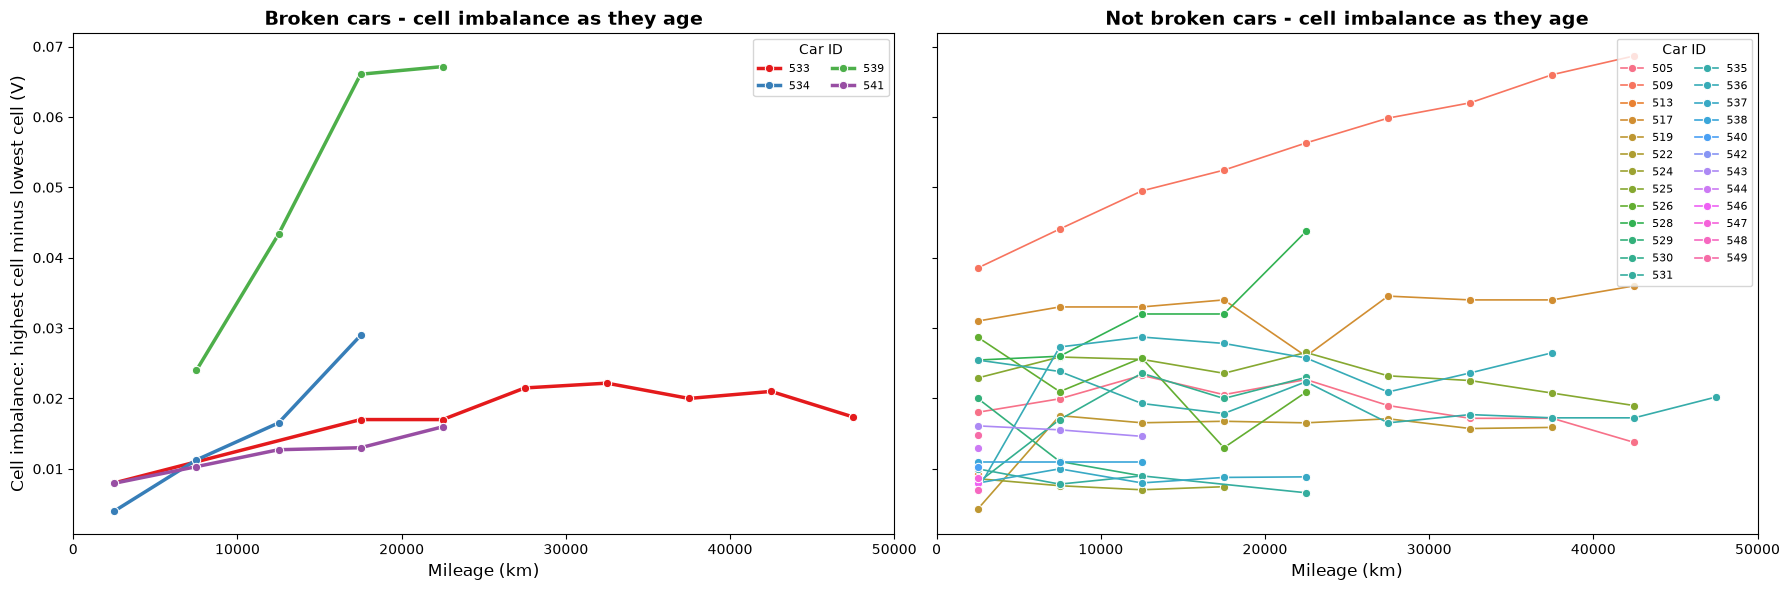

In [5]:
# one value per car per 5,000 km bin: the median of the signal in that bin (so one odd snippet does not move the line). Bins with under 5 snippets are skipped.
BIN = 5000
low["km_bin"] = (low["mileage"] // BIN) * BIN + BIN / 2
binned = low.groupby(["car", "label", "km_bin"]).agg(
    imbalance=("cell_volt_spread_mean", "median"), hottest=("max_temp_c_max", "median"), max_v=("max_cell_voltage", "median"),
    min_v=("min_cell_voltage", "median"), charge=("soc_mean", "median"), current=("avg_current", "median"), n=("mileage", "size")).reset_index()
binned = binned[binned["n"] >= 5].copy()
binned["Car ID"] = binned["car"].astype(str)

# --- GRAPH 1: cell imbalance as the cars age, every car its own line (like the 10 random cars graphs in work2) ---
fig, axes = plt.subplots(1, 2, figsize=(18, 6), sharey=True)
sns.lineplot(data=binned[binned["label"] == 1], x="km_bin", y="imbalance", hue="Car ID", palette="Set1", marker="o", linewidth=2.5, ax=axes[0])
axes[0].set_title("Broken cars - cell imbalance as they age", fontsize=14, fontweight="bold")
sns.lineplot(data=binned[binned["label"] == 0], x="km_bin", y="imbalance", hue="Car ID", palette="husl", marker="o", linewidth=1.2, ax=axes[1])
axes[1].set_title("Not broken cars - cell imbalance as they age", fontsize=14, fontweight="bold")
for ax in axes:
    ax.set_xlabel("Mileage (km)", fontsize=12)
    ax.set_ylabel("Cell imbalance: highest cell minus lowest cell (V)", fontsize=12)
    ax.set_xlim(0, 50000)
    ax.legend(title="Car ID", fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

In [6]:
# From this graph you can see
# Car 539's imbalance climbs from 0.024 V at 7,500 km to 0.067 V by 20,000 km, about 3 times what a typical not broken car has (0.02 V).
# Car 534 climbs too, from 0.008 V to 0.029 V by 17,500 km. Cars 533 and 541 stay flat around 0.01 to 0.02 V like most not broken cars.
# BUT on the right there is a not broken car (509) that climbs the same way, from 0.039 V to 0.070 V over 45,000 km, and 517 sits at 0.035 V.
# So a climbing imbalance is not unique to broken cars. What 539 and 534 share is that they start where everybody starts and then leave the pack.
# This is the first signal that looks like the battery and not the driver, but with 1 not broken car doing the same it is a lead, not a rule.

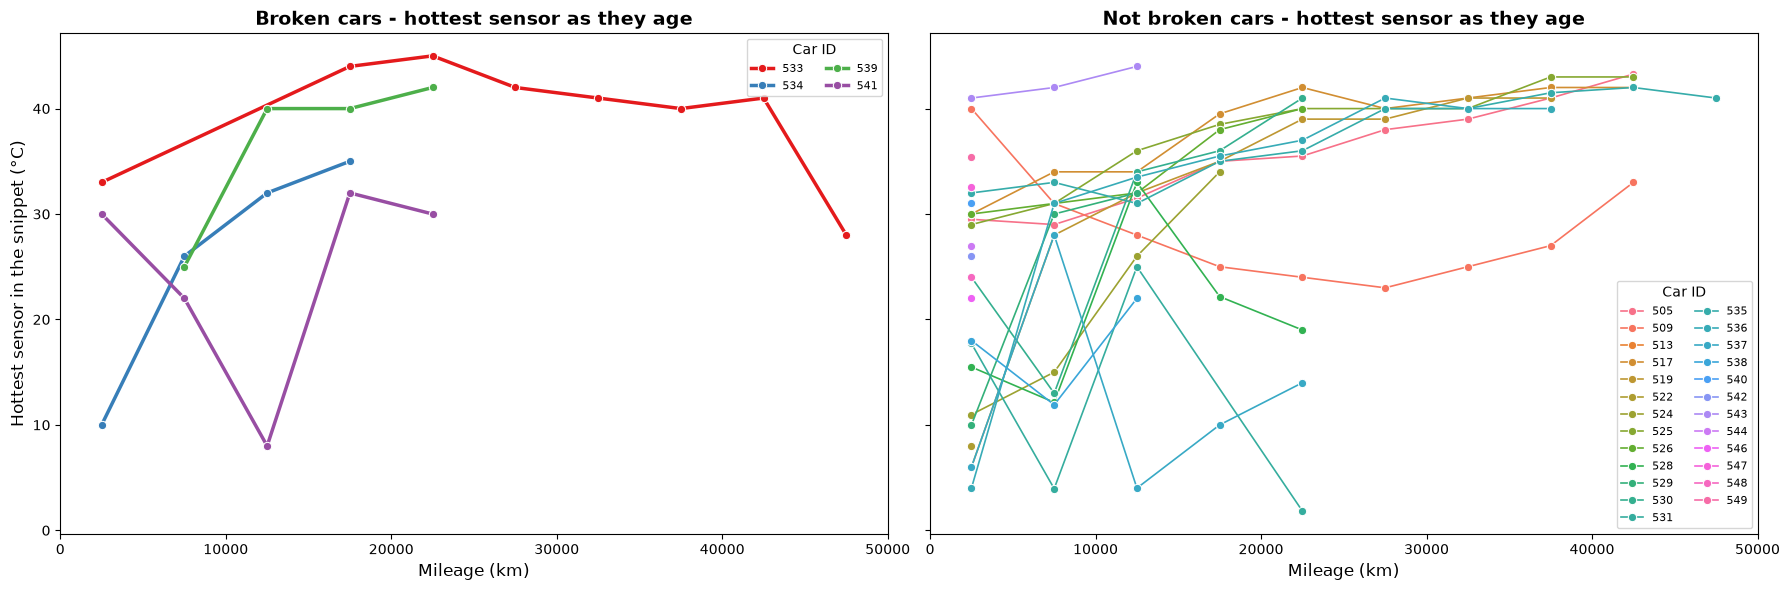

In [7]:
# --- GRAPH 2: hottest temperature sensor as the cars age ---
fig, axes = plt.subplots(1, 2, figsize=(18, 6), sharey=True)
sns.lineplot(data=binned[binned["label"] == 1], x="km_bin", y="hottest", hue="Car ID", palette="Set1", marker="o", linewidth=2.5, ax=axes[0])
axes[0].set_title("Broken cars - hottest sensor as they age", fontsize=14, fontweight="bold")
sns.lineplot(data=binned[binned["label"] == 0], x="km_bin", y="hottest", hue="Car ID", palette="husl", marker="o", linewidth=1.2, ax=axes[1])
axes[1].set_title("Not broken cars - hottest sensor as they age", fontsize=14, fontweight="bold")
for ax in axes:
    ax.set_xlabel("Mileage (km)", fontsize=12)
    ax.set_ylabel("Hottest sensor in the snippet (°C)", fontsize=12)
    ax.set_xlim(0, 50000)
    ax.legend(title="Car ID", fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

In [8]:
# From this graph you can see
# Temperature on its own does not split the groups. Car 533 is the hottest car in the whole set (typical hottest sensor 42 °C, above 96% of the
# not broken cars) and sits at 40 to 45 °C from 15,000 to 40,000 km, car 539 is at 40 °C from 15,000 km on. But the not broken cars are all over
# the place too (8 to 43 °C) because temperature follows how hard and when a car charges. I come back to temperature at the same charge level in graph 4.

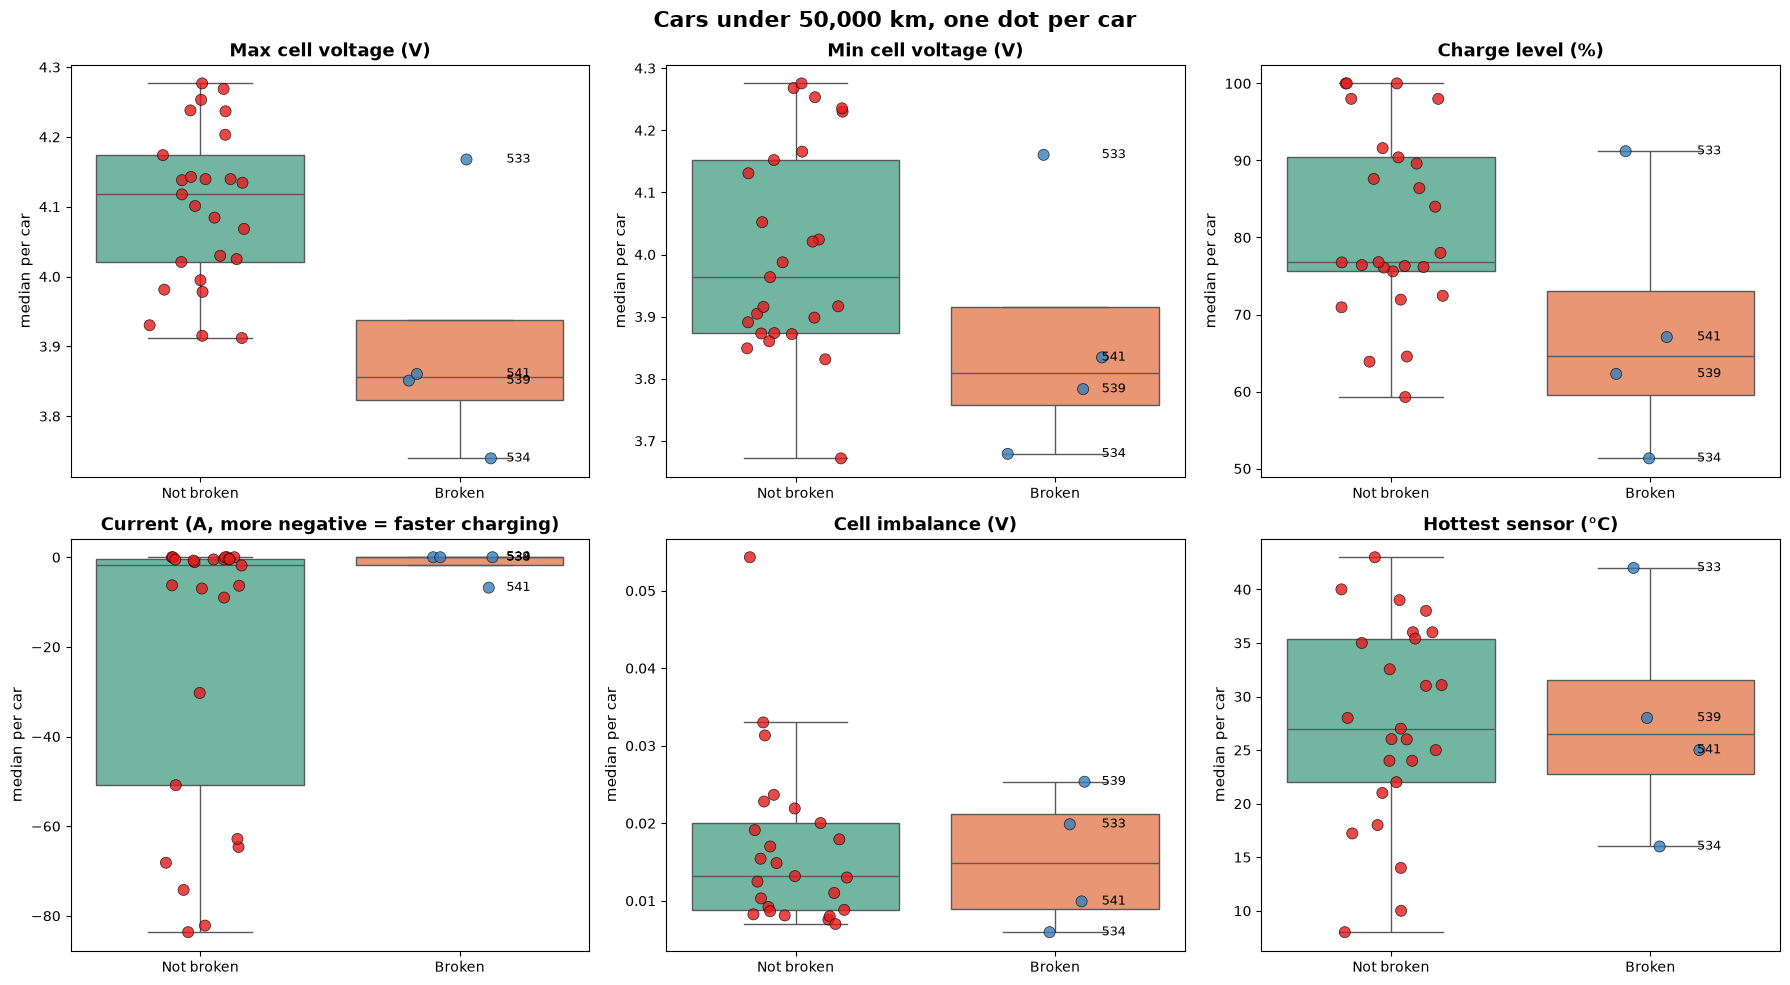

In [9]:
# --- GRAPH 3: one dot per car. Each car boiled down to the median of all its snippets under 50,000 km ---
per_car = low.groupby(["car", "label"], as_index=False)[["max_cell_voltage", "min_cell_voltage", "soc_mean", "avg_current", "cell_volt_spread_mean", "max_temp_c_max"]].median()
per_car["group"] = per_car["label"].map({0: "Not broken", 1: "Broken"})
NICE = {"max_cell_voltage": "Max cell voltage (V)", "min_cell_voltage": "Min cell voltage (V)", "soc_mean": "Charge level (%)",
        "avg_current": "Current (A, more negative = faster charging)", "cell_volt_spread_mean": "Cell imbalance (V)", "max_temp_c_max": "Hottest sensor (°C)"}

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, sig in zip(axes.flat, NICE):
    sns.boxplot(data=per_car, x="group", y=sig, hue="group", order=["Not broken", "Broken"], palette="Set2", legend=False, showfliers=False, ax=ax)
    sns.stripplot(data=per_car, x="group", y=sig, hue="group", order=["Not broken", "Broken"], palette="Set1", legend=False, size=8, alpha=0.8,
                  edgecolor="black", linewidth=0.5, jitter=0.2, ax=ax)
    for _, r in per_car[per_car["label"] == 1].iterrows():       # name the 4 broken cars
        ax.text(1.18, r[sig], str(int(r["car"])), fontsize=9, va="center")
    ax.set_title(NICE[sig], fontsize=13, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("median per car", fontsize=11)
plt.suptitle("Cars under 50,000 km, one dot per car", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

In [10]:
# From this graph you can see
# Max cell voltage LOOKS like a strong signal: 534, 539 and 541 sit under 3.95 V while the typical not broken car reaches 4.12 V. Min cell voltage, same picture.
# But look at the charge level panel: the same 3 cars are kept at a lower charge level (typical 51 to 67%, the typical not broken car is at 77%)
# and voltage just follows the charge level. So the low voltage is how the car is used, not the battery. Car 533 is the odd one out at 91% charge.
# Current: the typical snippet of the broken cars is 0 to -7 A (sitting at the charger or trickle charging) while many not broken cars sit at -50 to -80 A
# (fast charging). So the broken cars do NOT fast charge more than the others, the "fast charging kills batteries" story does not fit these 4 cars.
# Imbalance and temperature medians overlap, because a car's median mixes its whole life and every charge level. Graph 1 showed what the median hides.

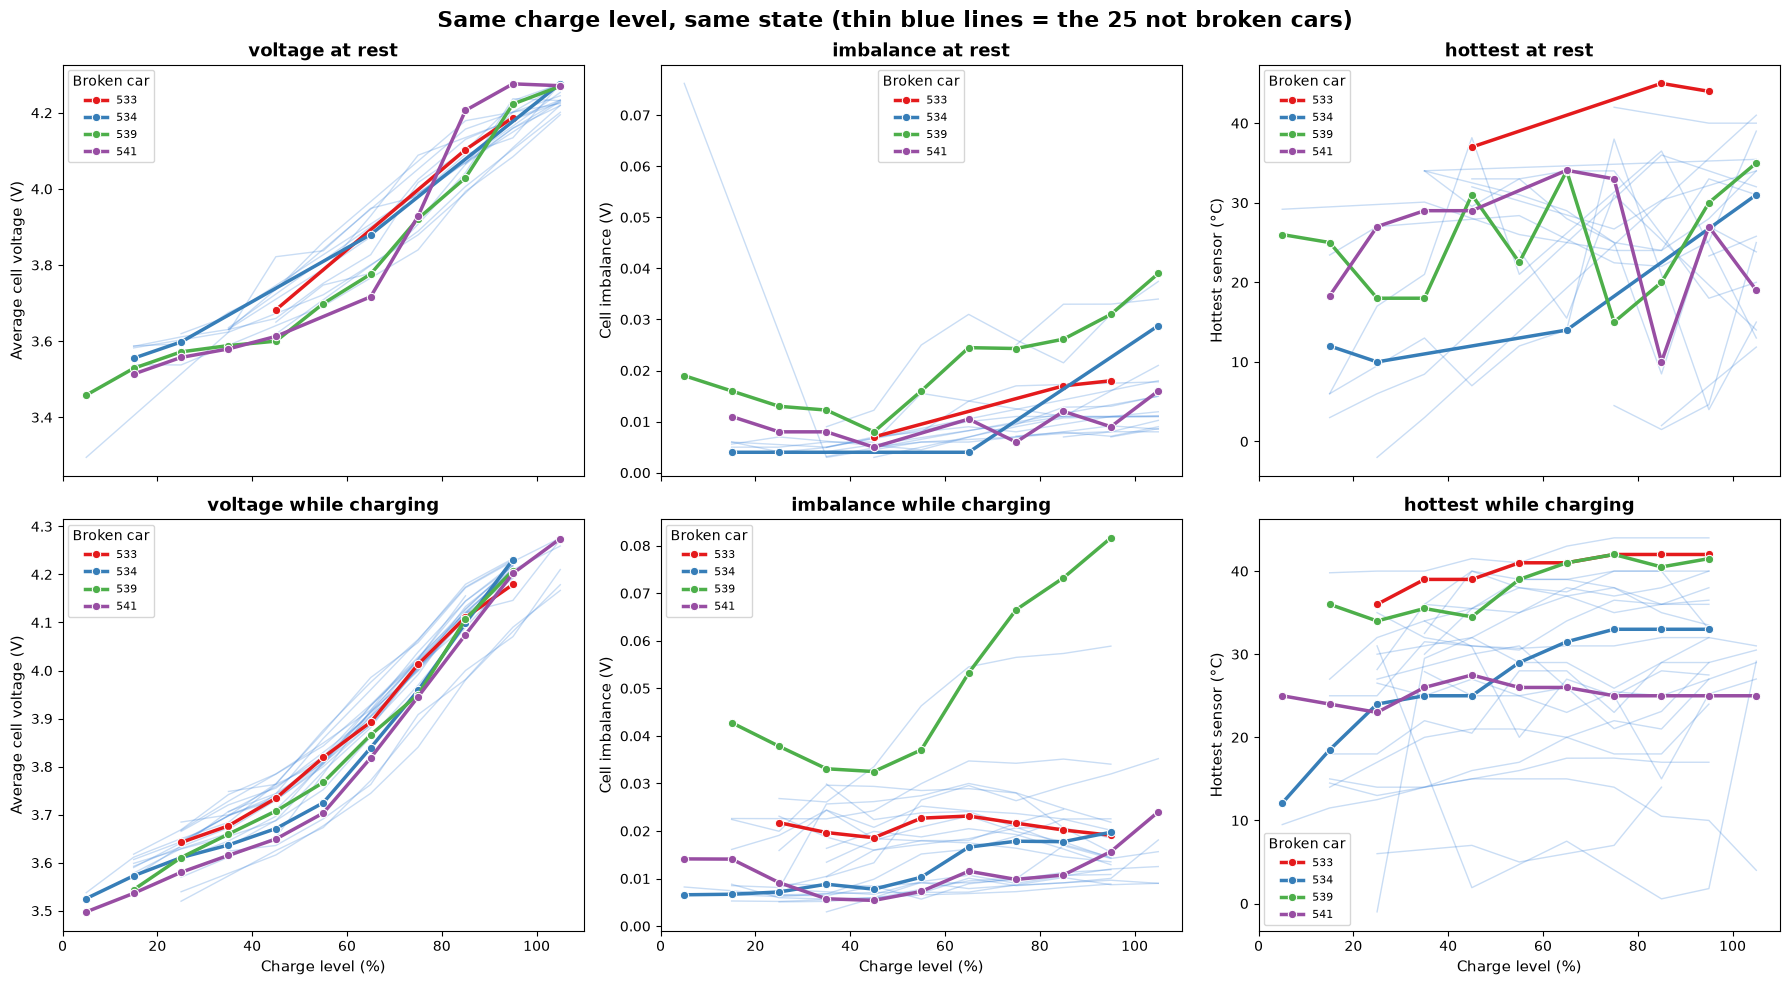

In [11]:
# --- GRAPH 4: the same signals at the SAME charge level ---
# Voltage follows the charge level and the broken cars sit at a lower charge level, so a lower typical voltage proves nothing. Here I bin the snippets by
# charge level (10% bins) and take each car's median voltage, imbalance and temperature per bin, once at rest (no current flowing) and once while charging.
# If the cells had aged or one cell is weak, the voltage or the imbalance at the same charge level should be different, and that would NOT be explained by usage.
low["soc_bin"] = (low["soc_mean"] // 10) * 10 + 5
by_soc = low.groupby(["car", "label", "charging", "soc_bin"]).agg(voltage=("avg_cell_voltage", "median"), imbalance=("cell_volt_spread_mean", "median"),
                                                                  hottest=("max_temp_c_max", "median"), n=("car", "size")).reset_index()
by_soc = by_soc[by_soc["n"] >= 5].copy()
by_soc["Car ID"] = by_soc["car"].astype(str)

fig, axes = plt.subplots(2, 3, figsize=(18, 10), sharex=True)
for r, (chg, state) in enumerate([(False, "at rest"), (True, "while charging")]):
    for ax, sig in zip(axes[r], ["voltage", "imbalance", "hottest"]):
        part = by_soc[by_soc["charging"] == chg]
        # not broken cars as one blue line per car in the background, the 4 broken cars in colour on top
        sns.lineplot(data=part[part["label"] == 0], x="soc_bin", y=sig, units="car", estimator=None, color="#2a78d6", alpha=0.25, linewidth=1, ax=ax, legend=False)
        sns.lineplot(data=part[part["label"] == 1], x="soc_bin", y=sig, hue="Car ID", palette="Set1", marker="o", linewidth=2.5, ax=ax)
        ax.set_title(f"{sig} {state}", fontsize=13, fontweight="bold")
        ax.set_xlabel("Charge level (%)", fontsize=11)
        ax.set_ylabel({"voltage": "Average cell voltage (V)", "imbalance": "Cell imbalance (V)", "hottest": "Hottest sensor (°C)"}[sig], fontsize=11)
        ax.legend(title="Broken car", fontsize=8)
plt.suptitle("Same charge level, same state (thin blue lines = the 25 not broken cars)", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

In [12]:
# From this graph you can see (this is the graph I trust most)
# Voltage at the same charge level: the 4 broken cars sit right on top of the blue lines, at rest and while charging. So their cells hold a normal
# voltage for their charge level. The low voltages in graph 3 were purely the low charge level. Max and min cell voltage are NOT a battery signal here.
# Imbalance at the same charge level: car 539 is above all but one of the not broken cars while charging (0.03 to 0.08 V against mostly 0.01 to 0.02 V) at every charge level,
# and above most of them at rest from 50% up. Car 534 is above the pack at rest from 60% up. 533 and 541 are inside the pack.
# A spread between cells that grows with the charge level and under current is what a weak or aged cell looks like.
# Temperature while charging: 533 and 539 run about 10 °C hotter than the typical not broken car at every charge level (35 to 42 °C against 25 to 31 °C).
# Car 541 is normal on every one of these. If it has a battery problem it is not visible in these signals.

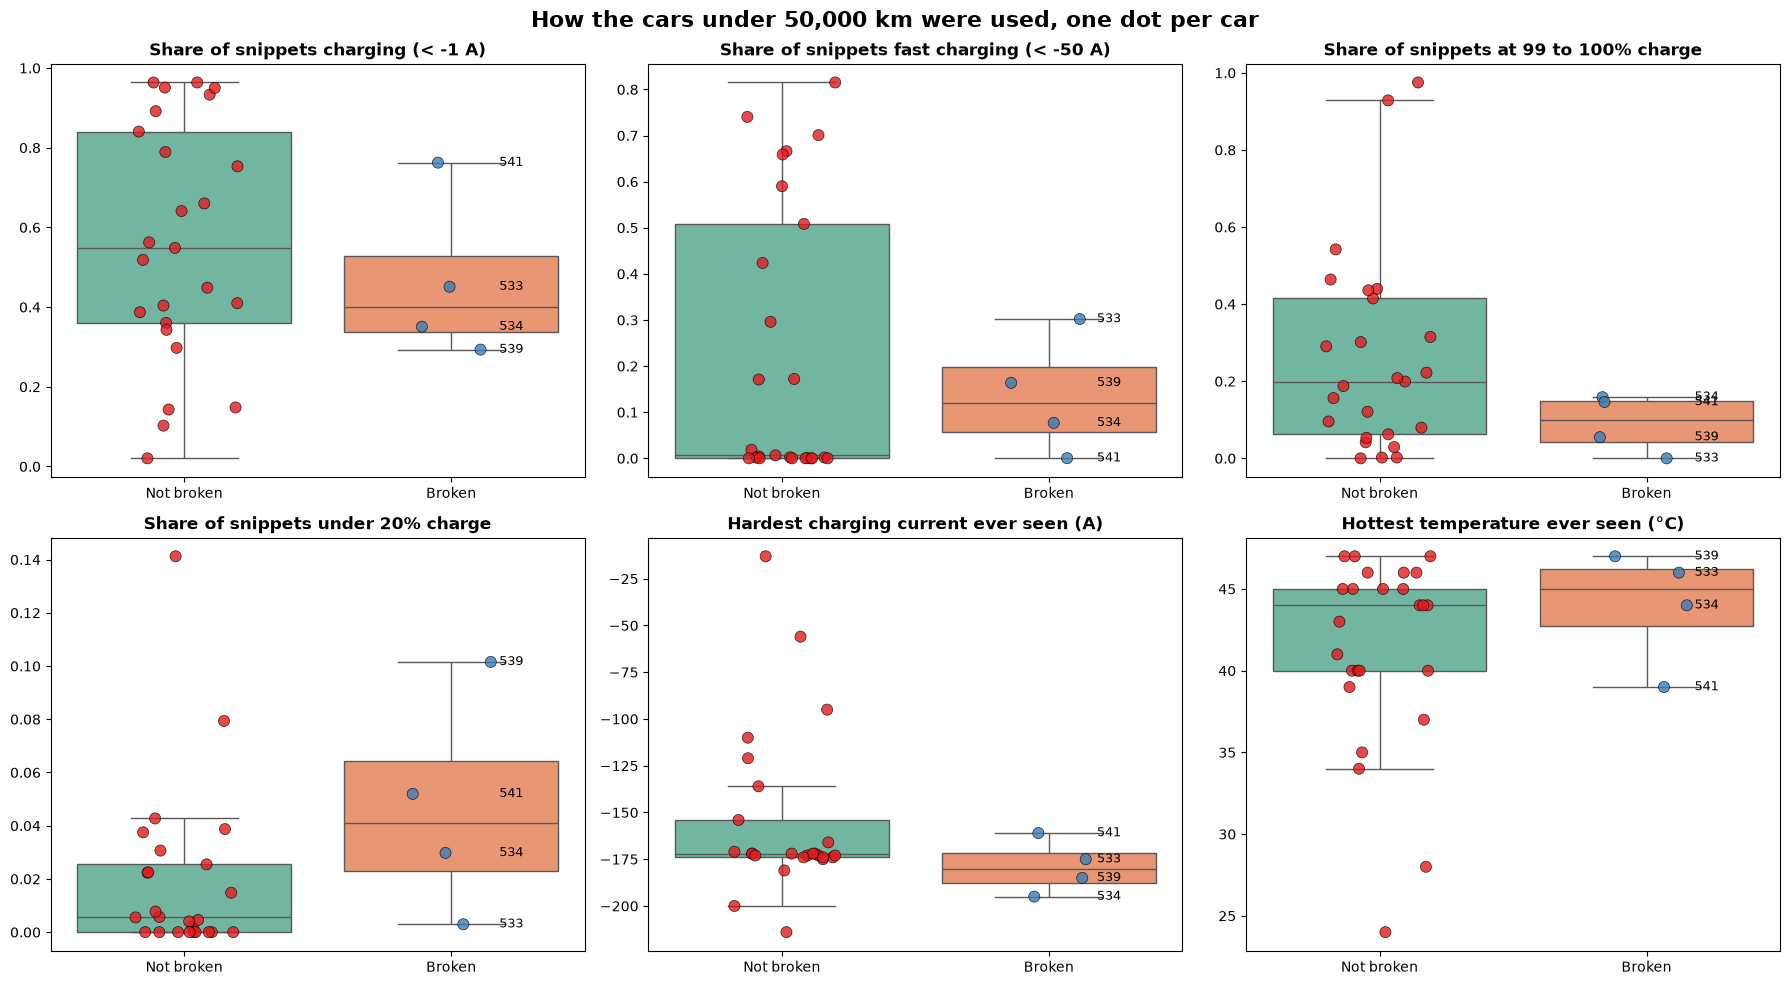

,label,share_charging,share_fast,share_full,share_low,hardest_current,hottest_ever,group
car,,,,,,,,
541,1,0.76,0.00,0.15,0.05,-161.0,39.0,Broken
533,1,0.45,0.30,0.00,0.00,-175.0,46.0,Broken
534,1,0.35,0.08,0.16,0.03,-195.0,44.0,Broken
539,1,0.29,0.16,0.05,0.10,-185.0,47.0,Broken
525,0,0.96,0.74,0.00,0.00,-173.0,47.0,Not broken
505,0,0.96,0.70,0.00,0.00,-173.0,47.0,Not broken
535,0,0.95,0.82,0.06,0.00,-174.0,47.0,Not broken
543,0,0.95,0.51,0.03,0.04,-173.0,46.0,Not broken
509,0,0.93,0.67,0.08,0.00,-172.0,45.0,Not broken


In [13]:
# --- GRAPH 5: how was each car used? ---
# share of snippets charging, fast charging, parked full, parked nearly empty, the hardest current the car ever took and the hottest it ever got
habits = (low.assign(fast=low["avg_current"] < -50, full=low["soc_mean"] >= 99, lowc=low["soc_mean"] < 20)
             .groupby(["car", "label"]).agg(share_charging=("charging", "mean"), share_fast=("fast", "mean"), share_full=("full", "mean"),
                                            share_low=("lowc", "mean"), hardest_current=("current_min", "min"), hottest_ever=("max_temp_c_max", "max")).reset_index())
habits["group"] = habits["label"].map({0: "Not broken", 1: "Broken"})
HAB = {"share_charging": "Share of snippets charging (< -1 A)", "share_fast": "Share of snippets fast charging (< -50 A)",
       "share_full": "Share of snippets at 99 to 100% charge", "share_low": "Share of snippets under 20% charge",
       "hardest_current": "Hardest charging current ever seen (A)", "hottest_ever": "Hottest temperature ever seen (°C)"}

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, h in zip(axes.flat, HAB):
    sns.boxplot(data=habits, x="group", y=h, hue="group", order=["Not broken", "Broken"], palette="Set2", legend=False, showfliers=False, ax=ax)
    sns.stripplot(data=habits, x="group", y=h, hue="group", order=["Not broken", "Broken"], palette="Set1", legend=False, size=8, alpha=0.8,
                  edgecolor="black", linewidth=0.5, jitter=0.2, ax=ax)
    for _, r in habits[habits["label"] == 1].iterrows():
        ax.text(1.18, r[h], str(int(r["car"])), fontsize=9, va="center")
    ax.set_title(HAB[h], fontsize=12, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("")
plt.suptitle("How the cars under 50,000 km were used, one dot per car", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()
habits.set_index("car").sort_values(["label", "share_charging"], ascending=[False, False]).round(2)

In [14]:
# From this graph you can see
# Time nearly empty: 3 of the 4 broken cars spend 3 to 10% of their snippets under 20% charge (539: 10%, 541: 5%, 534: 3%). The typical not broken car
# spends 0.5% there and only one not broken car (519, 14%) is above them. 533 again does not fit (0.3%).
# Time full: all 4 broken cars are below the typical not broken car (16% or less of their snippets at 99 to 100%, typical 20%).
# Fast charging, hardest current, hottest ever: no difference. Every car in the set has seen about -170 A and 40 to 47 °C at some point,
# so the broken cars were not treated more harshly in those terms.
# So the usage pattern that goes with "broken at low mileage" here is: driven down low, charged gently, not kept full. That could be a cause (deep
# discharge is a known stress), a consequence (a pack that is losing capacity runs low more often) or just how 3 owners drive. The data cannot tell those apart.

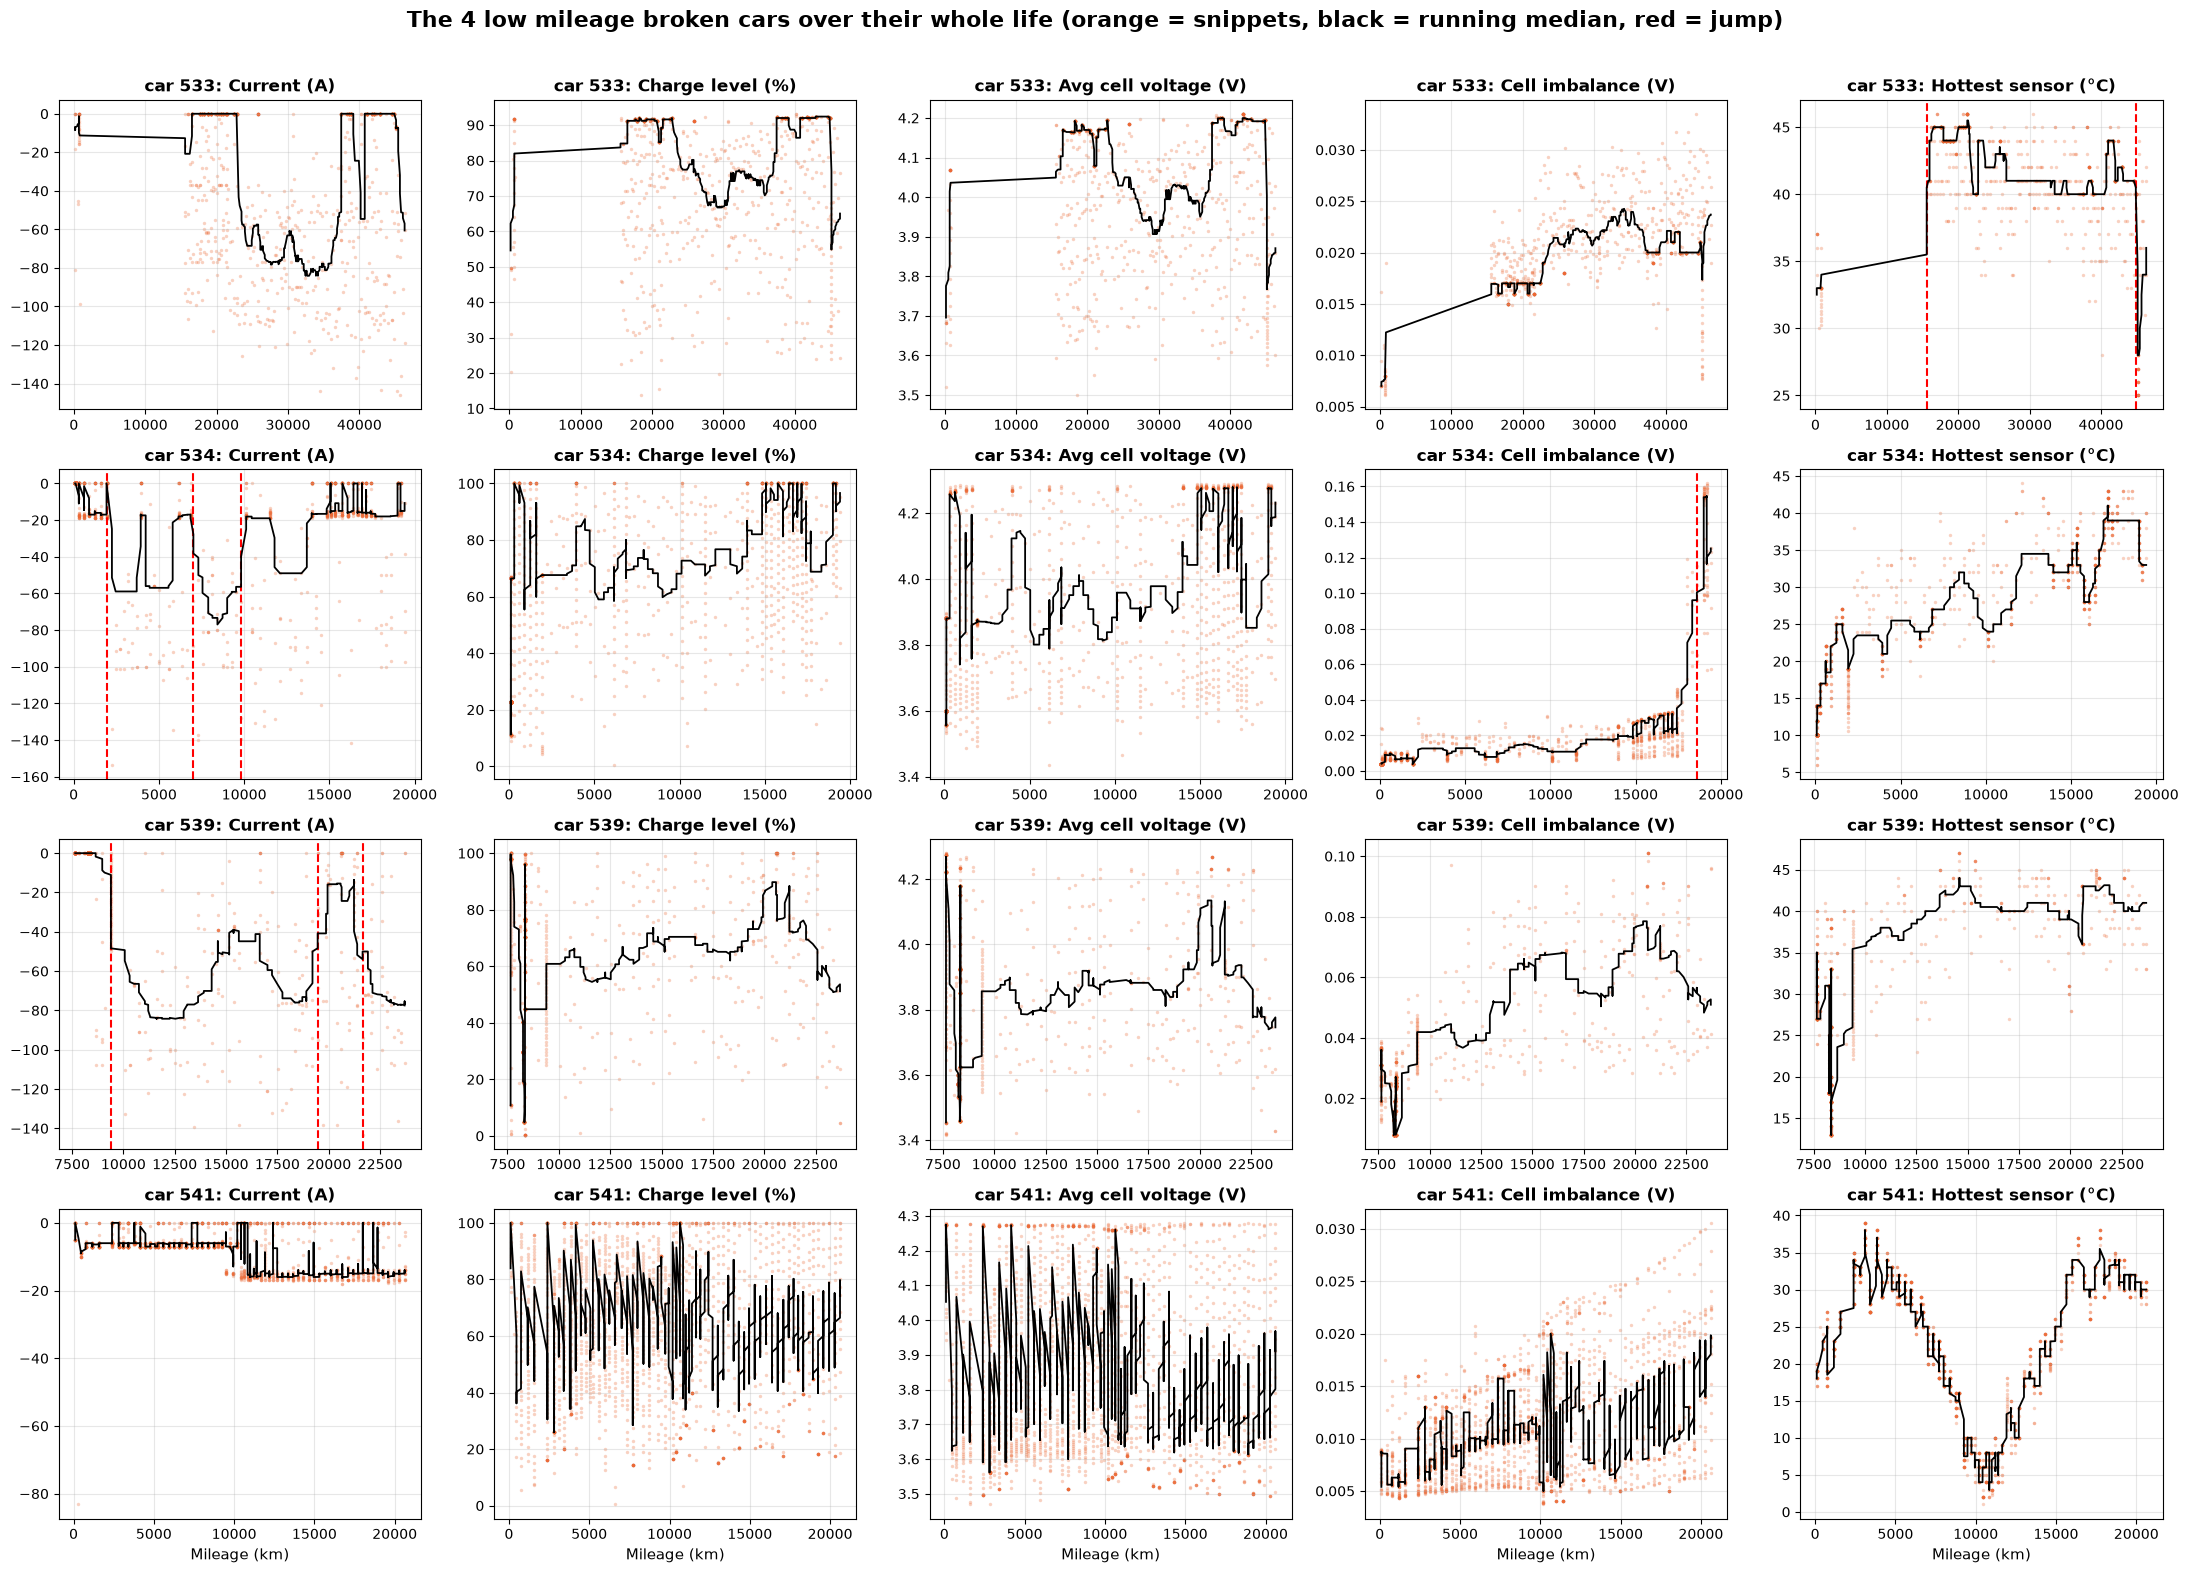

9 jumps found


,car,what jumped,mileage,before,after,score,where_in_life
0,534,Cell imbalance (V),18591,0.042,0.153,11.7,0.96
1,534,Current (A),1928,0.000,-58.928,-4.8,0.59
2,534,Current (A),7021,-17.000,-76.953,-4.8,0.67
3,534,Current (A),9819,-76.953,-18.402,4.7,0.69
4,533,Hottest sensor (°C),44878,41.000,28.000,-4.4,0.95
5,539,Current (A),19457,-76.000,-15.801,4.4,0.89
6,539,Current (A),21644,-13.692,-72.490,-4.3,0.96
7,539,Current (A),9393,-25.000,-83.188,-4.2,0.73
8,533,Hottest sensor (°C),15584,33.000,45.000,4.0,0.03


In [15]:
# --- GRAPH 6: the 4 broken cars over their whole life, where do the signals jump? ---
# Same jump search as before: snippets in mileage order, at every snippet compare the median of the NEXT 40 snippets with the median of the PREVIOUS 40,
# divide by the car's normal wobble (IQR / 1.349). A score of 4 or more gets a red dashed line (max 3 per signal per car, at least 40 snippets apart).
W, T, K = 40, 4.0, 3
JUMP = {"avg_current": "Current (A)", "soc_mean": "Charge level (%)", "avg_cell_voltage": "Avg cell voltage (V)",
        "cell_volt_spread_mean": "Cell imbalance (V)", "max_temp_c_max": "Hottest sensor (°C)"}


def jump_score(values):
    s = pd.Series(np.asarray(values, dtype=float))
    before = s.rolling(W, min_periods=W // 2).median().shift(1)       # median of the previous W snippets
    after = s[::-1].rolling(W, min_periods=W // 2).median()[::-1]     # median of the next W snippets
    wobble = (s.quantile(0.75) - s.quantile(0.25)) / 1.349
    if not wobble > 0:
        wobble = s.std() if s.std() > 0 else 1.0
    return (after - before) / wobble, before, after


jumps = []
fig, axes = plt.subplots(len(broken), len(JUMP), figsize=(22, 4 * len(broken)))
for r, car in enumerate(broken):
    d = low[low["car"] == car].reset_index(drop=True)
    for ax, sig in zip(axes[r], JUMP):
        score, before, after = jump_score(d[sig])
        found = []
        for i, v in score.abs().sort_values(ascending=False).items():   # strongest jumps first, at least W apart
            if not v >= T or len(found) == K:
                break
            if all(abs(i - j) >= W for j in found):
                found.append(i)
        for i in found:
            ax.axvline(d.loc[i, "mileage"], color="red", linestyle="--", linewidth=1.5)
            jumps.append({"car": car, "what jumped": JUMP[sig], "mileage": round(d.loc[i, "mileage"]), "before": round(before[i], 3),
                          "after": round(after[i], 3), "score": round(score[i], 1), "where_in_life": round(i / len(d), 2)})
        show = d if len(d) <= 2000 else d.sample(2000, random_state=42)
        ax.scatter(show["mileage"], show[sig], s=6, alpha=0.3, color="#eb6834", linewidths=0)
        ax.plot(d["mileage"], d[sig].rolling(W, min_periods=W // 2, center=True).median(), color="black", linewidth=1.3)
        ax.set_title(f"car {car}: {JUMP[sig]}", fontsize=12, fontweight="bold")
        ax.grid(alpha=0.3)
for ax in axes[-1]:
    ax.set_xlabel("Mileage (km)", fontsize=11)
plt.suptitle("The 4 low mileage broken cars over their whole life (orange = snippets, black = running median, red = jump)", fontsize=16, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

jumps = pd.DataFrame(jumps).sort_values("score", key=np.abs, ascending=False).reset_index(drop=True)
print(len(jumps), "jumps found")
jumps

In [16]:
# From this graph you can see
# Most red lines are in current: the car switching between sitting at the charger and fast charging (534 between 2,000 and 10,000 km, 539 between
# 9,000 and 22,000 km). The two temperature jumps in 533 are the start (15,600 km) and the end (44,900 km) of its long hot fast charging period.
# The one that stands out is car 534: cell imbalance jumps from 0.04 V to 0.15 V at 18,600 km, in the last 4% of its recording, and nothing else jumps
# there. The black line climbs all the way from 0.01 V at 10,000 km to 0.15 V at the end. That is the shape of one cell drifting away from the rest,
# and it is the closest thing to a fault event in this set. 539's imbalance also rises over its life (0.03 to 0.07 V) but smoothly, 533 drifts up slowly, 541 stays flat.

In [17]:
# one number per signal: can it tell the 4 broken cars from the 25 not broken ones at all?
# AUC = pick one broken and one not broken car at random, how often is the broken car the higher one. 0.5 = coin flip, 1.0 = always higher, 0.0 = always lower.
SIGNALS = {"max_cell_voltage": "Max cell voltage", "avg_cell_voltage": "Avg cell voltage", "min_cell_voltage": "Min cell voltage", "soc_mean": "Charge level",
           "avg_current": "Current", "cell_volt_spread_mean": "Cell imbalance (median)", "max_temp_c_max": "Hottest sensor", "temp_spread": "Temperature spread",
           "voltage_gap": "Voltage change in snippet"}
med = low.groupby(["car", "label"], as_index=False)[list(SIGNALS)].median()
rows = []
for sig, name in SIGNALS.items():
    a = med.loc[med["label"] == 1, sig].values[:, None]
    b = med.loc[med["label"] == 0, sig].values[None, :]
    rows.append({"signal": name, "typical not broken car": med.loc[med["label"] == 0, sig].median(), "typical broken car": med.loc[med["label"] == 1, sig].median(),
                 "AUC (broken higher)": (a > b).mean() + 0.5 * (a == b).mean()})
pd.DataFrame(rows).set_index("signal").round(3)

,typical not broken car,typical broken car,AUC (broken higher)
signal,,,
Max cell voltage,4.118,3.856,0.180
Avg cell voltage,4.021,3.844,0.190
Min cell voltage,3.964,3.809,0.230
Charge level,76.800,64.677,0.230
Current,-1.839,0.000,0.775
Cell imbalance (median),0.013,0.015,0.480
Hottest sensor,27.000,26.500,0.500
Temperature spread,2.133,1.914,0.290
Voltage change in snippet,0.016,0.002,0.240


In [18]:
# The voltages and the charge level are the furthest from a coin flip (AUC 0.18 to 0.23) but they are all the same thing: 3 cars kept at a low charge level.
# Graph 4 showed that at the same charge level the voltages are normal. Imbalance and temperature are at 0.48 and 0.50 on the medians, because the median
# hides the climb in 539 and 534 and the heat in 533 and 539. So a per car median is the wrong summary for those two, the trend over mileage is the right one.

In [19]:
# INTERESTING THINGS I FOUND THIS WEEK
# 1. The low voltages of the broken cars were a usage pattern, not the battery. 3 of the 4 cars are kept at a low charge level, spend more time nearly empty
#    and less time full, and charge gently. At the same charge level their cell voltage is normal. This is the kind of difference that fools a model.
# 2. Cell imbalance is the best battery-side lead. In 539 and 534 the spread between the highest and lowest cell grows with mileage, sits above the not
#    broken cars at the same charge level, and 534 ends with a jump to 0.15 V. The old table could never show this because voltage_gap was not imbalance.
#    One not broken car (509) climbs the same way though, so this is a lead for the model, not a rule.
# 3. Two of the 4 cars (533, 539) run about 10 °C hotter while charging than the typical not broken car, at every charge level.
# 4. Car 541 looks normal on every signal. Whatever broke it is not in these 8 columns.
# 5. Fast charging does not explain these 4 cars. They fast charge less than many not broken cars and saw the same peak currents and temperatures.
#
# These are associations across 4 cars, not causes. Each pattern rests on 1 to 3 cars and for every pattern there is a not broken car that shows it too.
# The label is per car with no date, so I cannot tell if the imbalance grew before the fault or because of it, or if the low charge levels are a cause
# or a result of a pack that lost range. To say "cause" I would need the date of the first fault report per car, the repair record (which cell, BMS,
# cooling), capacity measurements over time, more low mileage broken cars, and not broken cars with the same usage to compare against.
#
# WHAT I WILL RESEARCH NEXT
# - work6: run the work4 cross validation only under 50,000 km to see if the model still separates the cars when mileage is held fixed.
# - Add two features from the raw columns the model has never used: how fast a car's cell imbalance grows over its last charging sessions, and its
#   charging temperature at a fixed charge level. Then check if they help the model on cars it has not seen.
# - Add "how the car is used" features (share of time under 20%, share of fast charging) to test whether the model has been reading usage instead of the battery.
# - Get more low mileage broken cars: the same figshare release has two more fleets (217 cars with 31 broken, 198 cars with 1 broken) in the same file format.